# Exercise 1: Embeddings and distances

Clustering aerial scenes with embeddings from a pre-trained vision transformer.

Two inputs, both from HuggingFace:

* **the images** - `blanchon/UC_Merced`, 2,100 aerial scenes in 21 classes
* **the embeddings** - `MustafaArikan/vit_embeddings_uc_merced_layers`, embedding vectors taken
  from 7 depths of a ViT (768 dims each)

## 1. Load the dataset

In [55]:
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import hf_hub_download

DATA = "blanchon/UC_Merced"

ds = load_dataset(DATA, split="train")
class_names = ds.features["label"].names
labels = np.array(ds["label"])

print(f"{len(ds)} images, {len(class_names)} classes")
print(class_names)

2100 images, 21 classes
['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


## 2. Embeddings

In [56]:
order = np.asarray(sorted(range(len(ds)), key=lambda i: (class_names[labels[i]], i)))
y_all = labels[order] + 1                      # 1-based, as in the embeddings

rng = np.random.default_rng(0)
train_idx, test_idx = [], []
for label in range(1, len(class_names) + 1):
    idx = np.where(y_all == label)[0]
    rng.shuffle(idx)
    n_test = max(1, int(round(len(idx) * 0.2)))
    test_idx += list(idx[:n_test])
    train_idx += list(idx[n_test:])

train_idx, test_idx = np.asarray(train_idx), np.asarray(test_idx)

print(f"train {len(train_idx)} / test {len(test_idx)}")

train 1680 / test 420


## 3. Align the training images

Some of the 2,100 images are a few pixels off 256 x 256, so they are resized here;
`np.stack` would fail otherwise.

In [57]:
def to_rgb(row):
    im = row["image"].convert("RGB")
    if im.size != (256, 256):
        im = im.resize((256, 256))
    return np.asarray(im)

X_train_rgb = np.stack([to_rgb(ds[int(i)]) for i in order[train_idx]])
y_train = y_all[train_idx]

print(X_train_rgb.shape, X_train_rgb.dtype)
print(y_train.shape)

(1680, 256, 256, 3) uint8
(1680,)


## 4. Load the embeddings

Seven depths are available. Index `0` is the patch embedding, before any attention;
`12` is the output of the last block.

In [58]:
REPO = "MustafaArikan/vit_embeddings_uc_merced_layers"
path = hf_hub_download(REPO, "vit_embeddings_uc_merced_layers.npz", repo_type="dataset")
d = np.load(path)

LAYERS = [0, 1, 2, 3, 6, 9, 12]
E_train = {k: d[f"E_train_l{k}"] for k in LAYERS}
E_test = {k: d[f"E_test_l{k}"] for k in LAYERS}

print("layers:", LAYERS)
print("dims  :", {k: v.shape for k, v in E_train.items()})
print("rows match the images:", np.array_equal(y_train, d["y_train"]))

layers: [0, 1, 2, 3, 6, 9, 12]
dims  : {0: (1680, 768), 1: (1680, 768), 2: (1680, 768), 3: (1680, 768), 6: (1680, 768), 9: (1680, 768), 12: (1680, 768)}
rows match the images: True


## 5. The 10 farthest neighbours of one image

Cosine similarity against every other training image, sorted ascending, take the first 10.
"Farthest" means the images the model considers least alike.

layer 3 | query: image 144  (airplane)

   1. image    59  agricultural     +0.872
   2. image    19  agricultural     +0.880
   3. image    45  agricultural     +0.887
   4. image     6  agricultural     +0.891
   5. image    68  agricultural     +0.907
   6. image   417  chaparral        +0.908
   7. image   407  chaparral        +0.908
   8. image   448  chaparral        +0.908
   9. image    36  agricultural     +0.909
  10. image   457  chaparral        +0.910


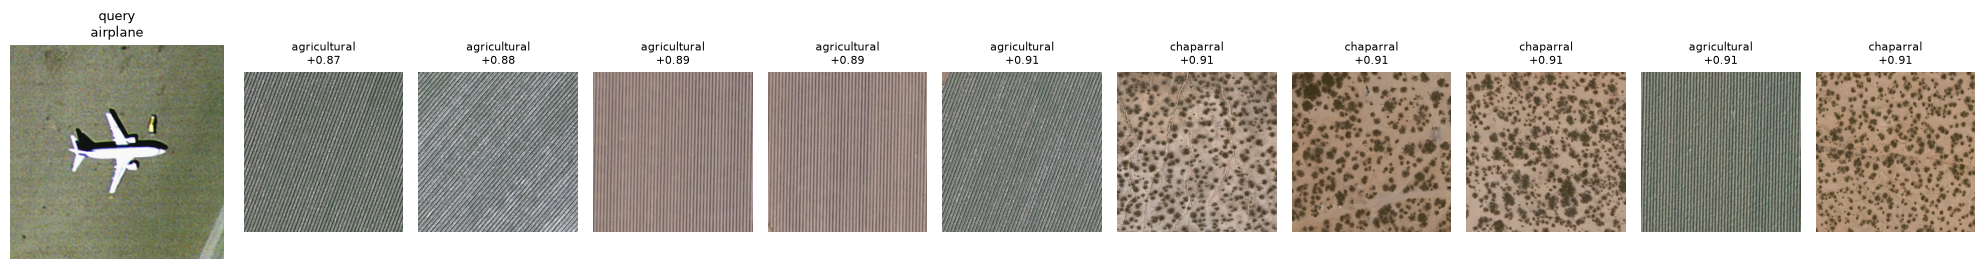

In [59]:
LAYER = 3                 # 0 = patch embeddings, 12 = last block
q = 144                   # query image index

E = E_train[LAYER]

norms = np.linalg.norm(E, axis=1)
sims = (E @ E[q]) / (norms * norms[q])

others = np.arange(len(E)) != q
farthest = np.where(others)[0][np.argsort(sims[others])][:10]

query_class = class_names[y_train[q] - 1]
print(f"layer {LAYER} | query: image {q}  ({query_class})\n")

for rank, j in enumerate(farthest, 1):
    print(f"  {rank:2}. image {j:5}  {class_names[y_train[j] - 1]:16} {sims[j]:+.3f}")

fig, axes = plt.subplots(1, 11, figsize=(20, 2.6),
                         gridspec_kw={"width_ratios": [1.4] + [1] * 10})

axes[0].imshow(X_train_rgb[q])
axes[0].set_title(f"query\n{query_class}", fontsize=9)
axes[0].axis("off")

for ax, j in zip(axes[1:], farthest):
    ax.imshow(X_train_rgb[j])
    ax.set_title(f"{class_names[y_train[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. TODO: the 10 nearest neighbours

Same computation, sorted the other way; take the first 10.

Then compare with the grid above:

* do the nearest neighbours share the query's class?
    * Yes, they are all airplane
* how much more alike are they than the farthest ones?
    * Very much, as there is an plane in all of them and in the farthest one there is not a single plane.

In [60]:
from scipy.spatial.distance import cdist

def get_nearest_neighbours(LAYER = 3, q = 144, method = "cosine"): 

    E = E_train[LAYER]

    norms = np.linalg.norm(E, axis=1)

    if method == "manhattan":
        sims = np.sum(np.abs(E - E[q]), axis=1)
    elif method == "correlation":
        sims = cdist(E, E[q].reshape(1, -1), metric='correlation').flatten()
    else: # cosine is the default
        sims = (E @ E[q]) / (norms * norms[q])
    
    others = np.arange(len(E)) != q

    # handle the different sorting of the measures
    if method in ["manhattan", "correlation"]:       
        closest = np.where(others)[0][np.argsort(sims[others])[:10]]
    else:        
        closest = np.where(others)[0][np.argsort(sims[others])[-10:][::-1]]


    query_class = class_names[y_train[q] - 1]
    print(f"layer {LAYER} | query: image {q}  ({query_class})\n")

    for rank, j in enumerate(closest, 1):
        print(f"  {rank:2}. image {j:5}  {class_names[y_train[j] - 1]:16} {sims[j]:+.3f}")

    fig, axes = plt.subplots(1, 11, figsize=(20, 2.6),
                            gridspec_kw={"width_ratios": [1.4] + [1] * 10})

    axes[0].imshow(X_train_rgb[q])
    axes[0].set_title(f"query\n{query_class}", fontsize=9)
    axes[0].axis("off")

    for ax, j in zip(axes[1:], closest):
        ax.imshow(X_train_rgb[j])
        ax.set_title(f"{class_names[y_train[j] - 1]}\n{sims[j]:+.2f}", fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

layer 3 | query: image 144  (airplane)

   1. image    86  airplane         +0.990
   2. image    87  airplane         +0.988
   3. image    89  airplane         +0.986
   4. image   141  airplane         +0.984
   5. image   155  airplane         +0.983
   6. image   131  airplane         +0.982
   7. image   106  airplane         +0.982
   8. image   113  airplane         +0.982
   9. image   134  airplane         +0.982
  10. image   103  airplane         +0.981


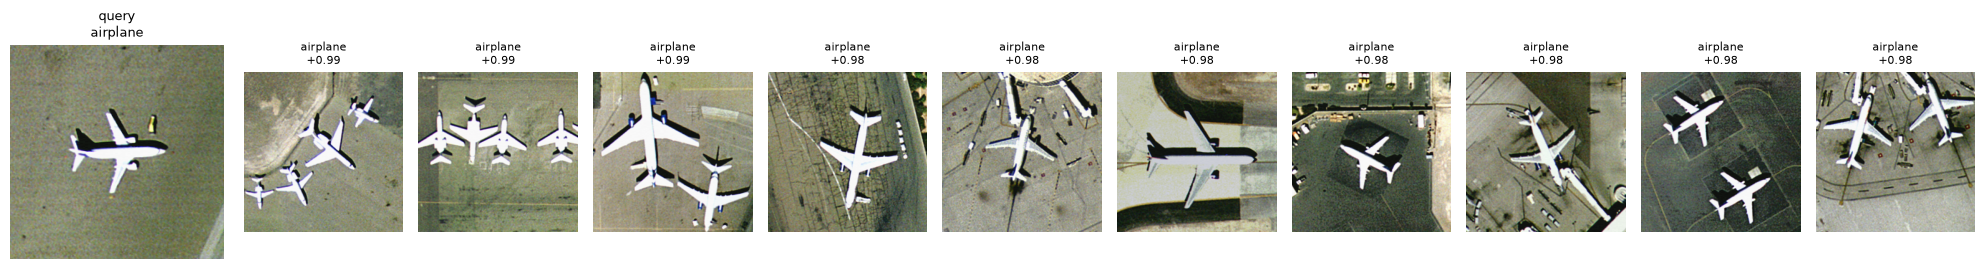

In [61]:
get_nearest_neighbours(3)

## 7. TODO: the same, for another layer

Repeat the 10 nearest for a different depth: try `LAYER = 1`, `6` and `12`.

Which depth returns neighbours that actually share the class?

* layer 1 returns images form two other classes but not from the target class
* layer 6 returns images all from the target class
* layer 12 returns images all from the target class and in every image there is exactly 1 plane, the same as in the target image

Whith each layer the nearest images get more similar to the target (for image 144)

layer 1 | query: image 144  (airplane)

   1. image   774  golfcourse       +0.999
   2. image   195  baseballdiamond  +0.999
   3. image   217  baseballdiamond  +0.999
   4. image   181  baseballdiamond  +0.999
   5. image   239  baseballdiamond  +0.999
   6. image   779  golfcourse       +0.999
   7. image   208  baseballdiamond  +0.999
   8. image   743  golfcourse       +0.999
   9. image   236  baseballdiamond  +0.999
  10. image   755  golfcourse       +0.999


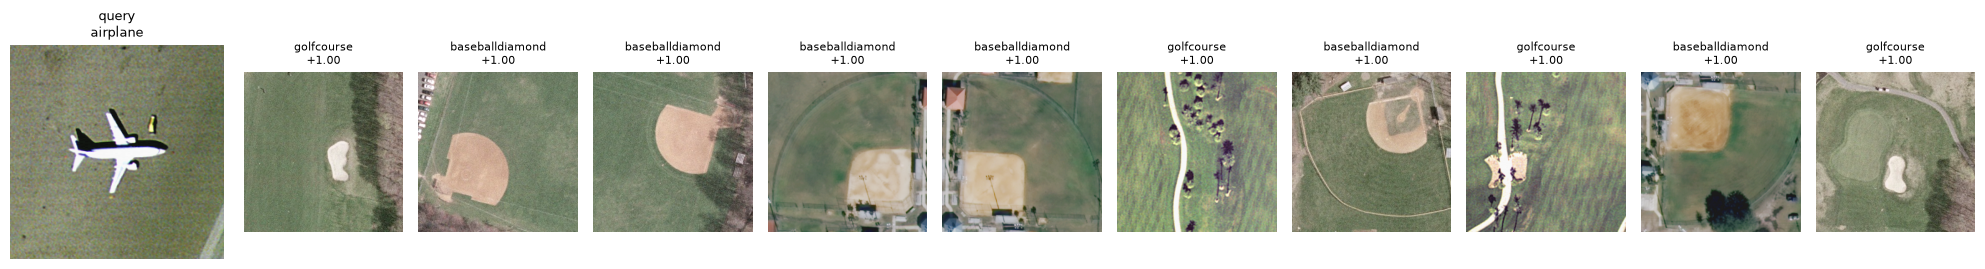

In [62]:
get_nearest_neighbours(1)

layer 6 | query: image 144  (airplane)

   1. image    86  airplane         +0.972
   2. image    89  airplane         +0.949
   3. image   141  airplane         +0.949
   4. image   155  airplane         +0.941
   5. image    83  airplane         +0.940
   6. image   103  airplane         +0.939
   7. image    98  airplane         +0.939
   8. image    87  airplane         +0.938
   9. image   133  airplane         +0.936
  10. image   152  airplane         +0.934


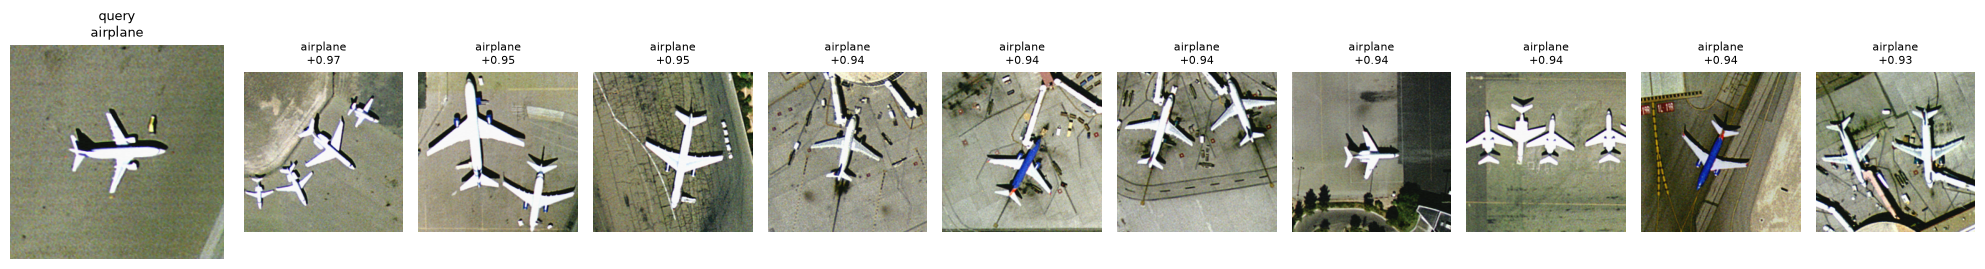

In [63]:
get_nearest_neighbours(6)

layer 12 | query: image 144  (airplane)

   1. image   158  airplane         +0.744
   2. image   145  airplane         +0.739
   3. image   147  airplane         +0.739
   4. image   120  airplane         +0.732
   5. image    98  airplane         +0.726
   6. image   108  airplane         +0.710
   7. image   150  airplane         +0.689
   8. image    90  airplane         +0.688
   9. image   101  airplane         +0.688
  10. image   131  airplane         +0.678


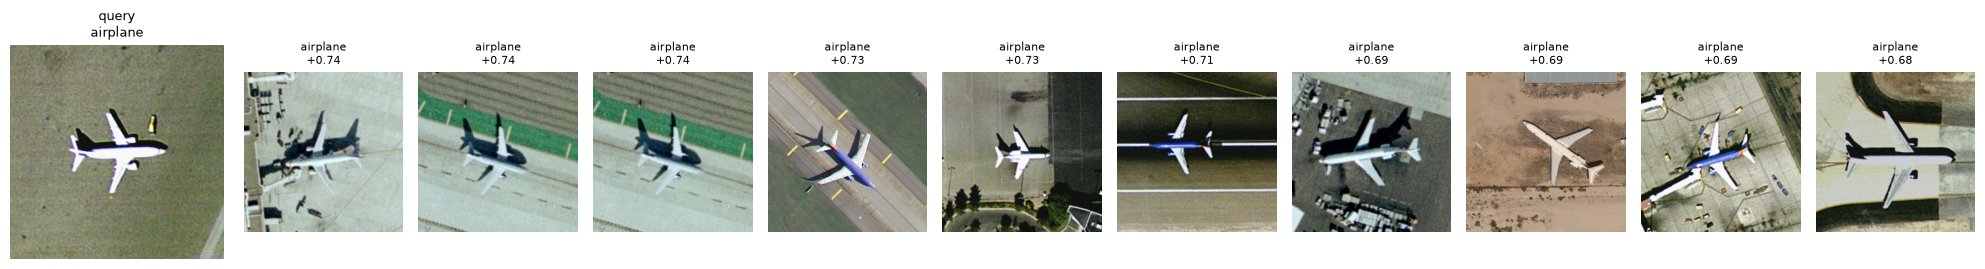

In [64]:
get_nearest_neighbours(12)

layer 6 | query: image 1280  (river)

   1. image  1291  river            +0.988
   2. image  1328  river            +0.951
   3. image  1288  river            +0.942
   4. image  1332  river            +0.942
   5. image  1296  river            +0.941
   6. image  1323  river            +0.939
   7. image  1354  river            +0.939
   8. image  1282  river            +0.938
   9. image  1309  river            +0.938
  10. image  1287  river            +0.936


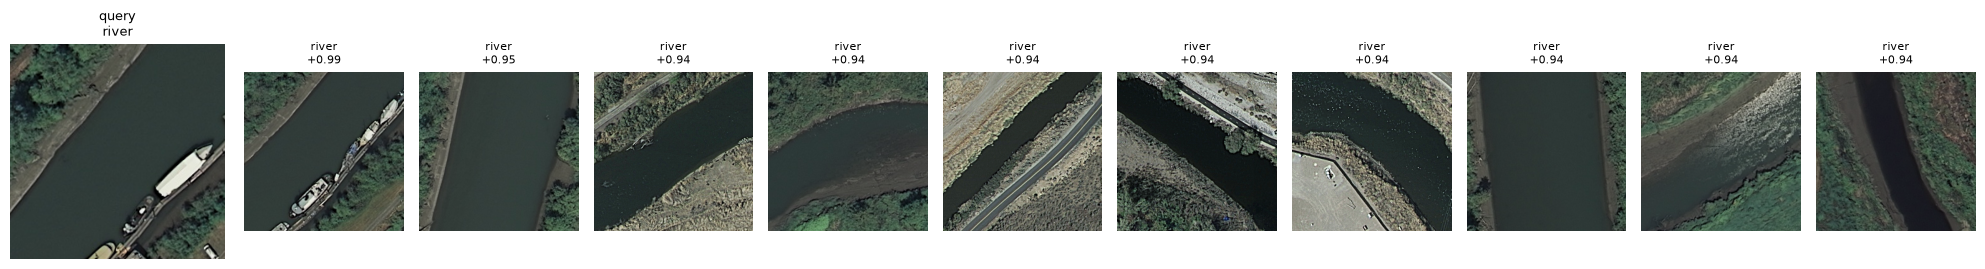

In [65]:
get_nearest_neighbours(LAYER = 6, q = 1280)

layer 12 | query: image 1280  (river)

   1. image  1291  river            +0.796
   2. image  1328  river            +0.593
   3. image  1358  river            +0.568
   4. image   700  freeway          +0.553
   5. image   889  intersection     +0.552
   6. image  1461  sparseresidential +0.534
   7. image   646  freeway          +0.529
   8. image  1290  river            +0.526
   9. image  1433  runway           +0.524
  10. image   695  freeway          +0.524


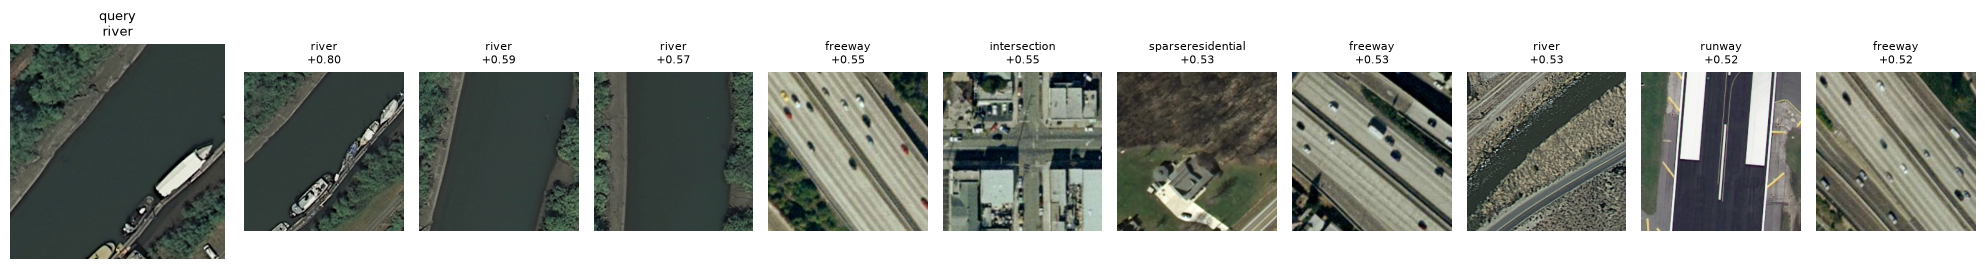

In [66]:
get_nearest_neighbours(LAYER=12, q = 1280)

For image 1280 (river), the higher layer (12) actually gets worse results than the lower layer (6)

The layer overfitted (domain shift)

## 8. TODO: another similarity measure

Cosine compares direction only and ignores magnitude. What else could you use to compare
two 768-dimensional vectors?

Find one alternative and show its 10 nearest for the same image:

e.g.
* Manhattan (L1), or correlation distance, does the ranking change?
* cosine and correlation bring the exact same order and manhattan has the same top 10 but slightly different order

Say in a sentence what each one assumes about the vectors.

* Cosine Similarity: Assumes only the proportional relationship (the angle) between features matters, completely ignoring the vector's overall magnitude or size.

* Manhattan Distance (L1): Assumes exact numerical values matter and calculates distance grid-style, penalizing differences linearly rather than exponentially.

* Correlation Distance: Assumes only the relative trend or shape of the features matters, ignoring the baseline average of the values.


layer 3 | query: image 144  (airplane)

   1. image    86  airplane         +0.990
   2. image    87  airplane         +0.988
   3. image    89  airplane         +0.986
   4. image   141  airplane         +0.984
   5. image   155  airplane         +0.983
   6. image   131  airplane         +0.982
   7. image   106  airplane         +0.982
   8. image   113  airplane         +0.982
   9. image   134  airplane         +0.982
  10. image   103  airplane         +0.981


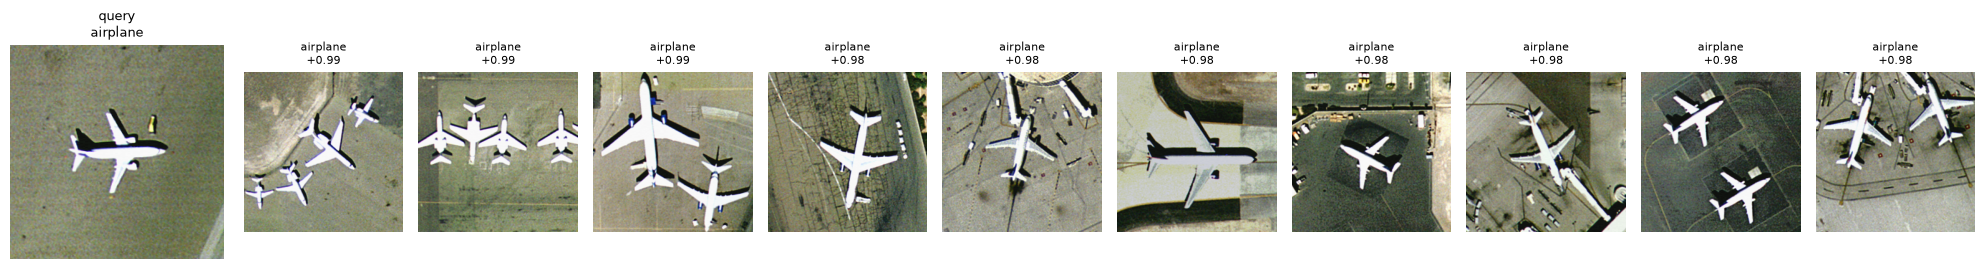

In [67]:
# cosine
get_nearest_neighbours()

layer 3 | query: image 144  (airplane)

   1. image    86  airplane         +150.377
   2. image    87  airplane         +168.377
   3. image    89  airplane         +178.894
   4. image   155  airplane         +192.263
   5. image   141  airplane         +192.474
   6. image   113  airplane         +200.582
   7. image   106  airplane         +202.379
   8. image   131  airplane         +202.766
   9. image   134  airplane         +206.064
  10. image   103  airplane         +207.540


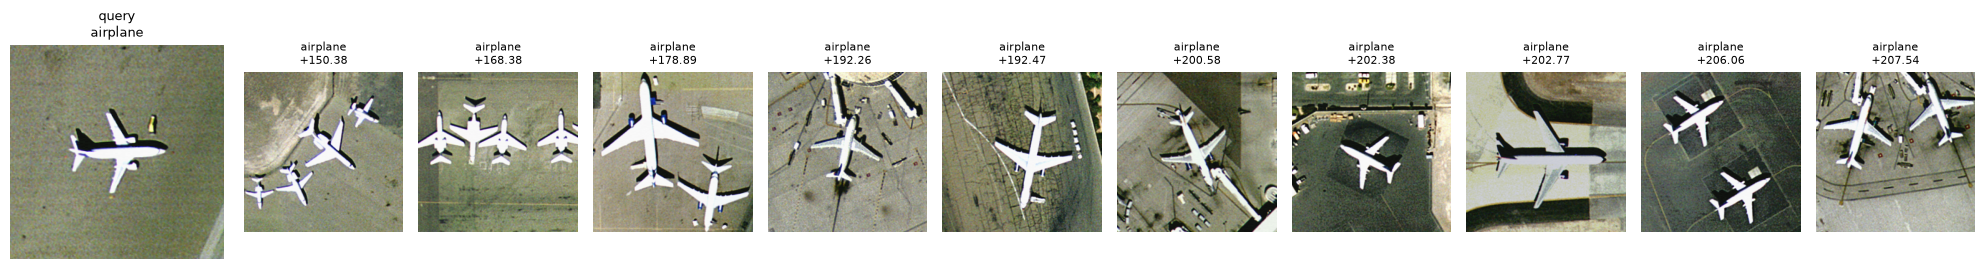

In [68]:
# manhattan
get_nearest_neighbours(method = "manhattan")

layer 3 | query: image 144  (airplane)

   1. image    86  airplane         +0.010
   2. image    87  airplane         +0.012
   3. image    89  airplane         +0.014
   4. image   141  airplane         +0.016
   5. image   155  airplane         +0.017
   6. image   131  airplane         +0.018
   7. image   106  airplane         +0.018
   8. image   113  airplane         +0.018
   9. image   134  airplane         +0.018
  10. image   103  airplane         +0.019


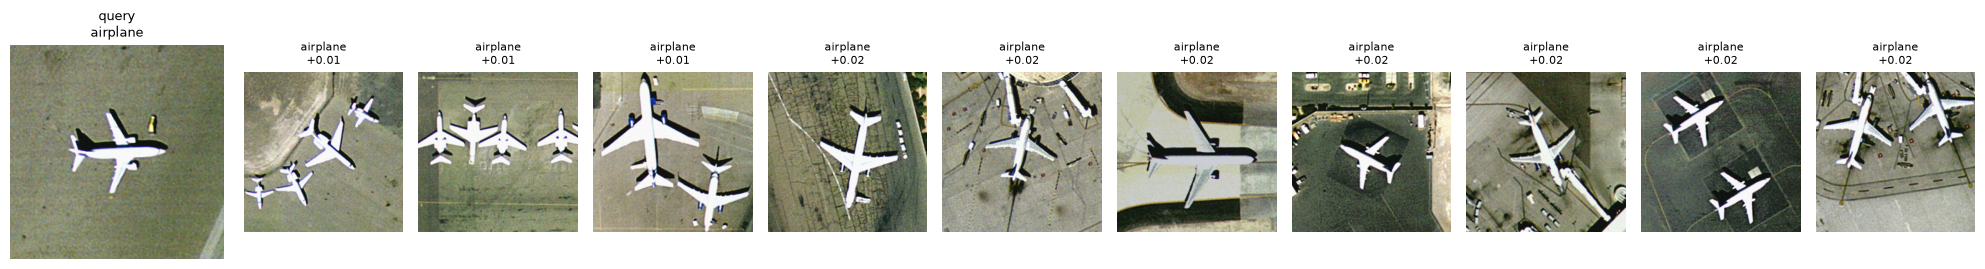

In [69]:
# correlation
get_nearest_neighbours(method = "correlation")